# TASK 4: SENTIMENT ANALYSIS USING MACHINE LEARNING

## Project Overview
This project uses Natural Language Processing (NLP) and machine learning to classify customer reviews into positive, negative, and neutral sentiment categories.

The dataset contains customer reviews and product ratings. Sentiment labels are created from ratings, and two machine learning classifiers are trained and evaluated.

## Objectives
- Inspect the dataset and sentiment class distribution.
- Clean and preprocess review text.
- Extract text features using TF-IDF.
- Split the data into training and testing sets using an 80:20 ratio.
- Train Naive Bayes and Logistic Regression classifiers.
- Evaluate accuracy, precision, recall, F1-score, and confusion matrices.
- Visualize sentiment distribution and WordClouds.
- Analyze five misclassified reviews.
- Compare models and discuss real-world applications.

## Tools and Technologies
- Python
- Pandas and NumPy
- Scikit-learn
- NLTK concepts for text preprocessing
- Matplotlib and Seaborn
- WordCloud
- Jupyter Notebook

## Dataset
Women's Clothing E-Commerce Reviews dataset from Kaggle.

Sentiment labels are derived from product ratings:
- Ratings 1–2: Negative
- Rating 3: Neutral
- Ratings 4–5: Positive

## Expected Outcome
A machine learning workflow that classifies customer reviews into three sentiment categories and evaluates model performance.

In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn wordcloud

Note: you may need to restart the kernel to use updated packages.


In [3]:
import re
import html
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Dataset Loading and Inspection

In this step, the customer review dataset is loaded into a Pandas DataFrame. The dataset is inspected to understand its dimensions, column names, data types, missing values, and sample records.

In [4]:
DATA_DIR = Path("data")
file_path = DATA_DIR / "sentiment_data.csv"

if not file_path.exists():
    csv_files = list(DATA_DIR.glob("*.csv"))
    if len(csv_files) == 1:
        file_path = csv_files[0]
    elif len(csv_files) == 0:
        raise FileNotFoundError(
            "No CSV found. Place the Kaggle CSV inside the data folder "
            "and name it sentiment_data.csv."
        )
    else:
        raise FileNotFoundError(
            "Multiple CSV files found. Keep only the dataset CSV in data "
            "or rename the correct file to sentiment_data.csv."
        )

try:
    df = pd.read_csv(file_path)
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin-1")

# Remove accidental spaces from column names.
df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully!")
print("File:", file_path)
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
File: data\Womens Clothing E-Commerce Reviews.csv
Rows and columns: (23486, 11)

Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

First five records:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


### Dataset Quality Check

Missing values can affect text processing, and duplicate records may cause repeated examples to influence model training. We inspect these issues before creating sentiment labels.

In [5]:
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Exact duplicate rows:", df.duplicated().sum())

print("\nRating distribution:")
if "Rating" in df.columns:
    display(df["Rating"].value_counts(dropna=False).sort_index())
else:
    raise KeyError(
        "The dataset does not contain a Rating column. "
        "Check the actual column names printed above."
    )

Missing values per column:


,Missing Values
Unnamed: 0,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14


Exact duplicate rows: 0

Rating distribution:


Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64

## 2. Data Preparation and Sentiment Label Creation

The dataset's ratings are converted into three sentiment categories.

- Ratings 1 and 2 represent negative sentiment.
- Rating 3 represents neutral sentiment.
- Ratings 4 and 5 represent positive sentiment.

These labels are proxies based on customer ratings, not manually verified sentiment labels. Rows without review text or valid ratings are removed before modelling.

In [6]:
# Find the required columns without depending on capitalization.
column_lookup = {col.strip().casefold(): col for col in df.columns}

review_col = column_lookup.get("review text")
rating_col = column_lookup.get("rating")
title_col = column_lookup.get("title")

if review_col is None or rating_col is None:
    raise KeyError(
        "Required columns not found. Expected 'Review Text' and 'Rating'. "
        f"Available columns: {df.columns.tolist()}"
    )

work_df = df.copy()

# Combine review title with review text if a Title column exists.
if title_col is not None:
    work_df["text"] = (
        work_df[title_col].fillna("").astype(str).str.strip()
        + " "
        + work_df[review_col].fillna("").astype(str).str.strip()
    ).str.strip()
else:
    work_df["text"] = work_df[review_col].fillna("").astype(str).str.strip()

work_df["rating_numeric"] = pd.to_numeric(
    work_df[rating_col], errors="coerce"
)

# Remove rows with empty text or invalid ratings.
work_df = work_df[
    work_df["text"].ne("")
    & work_df["rating_numeric"].isin([1, 2, 3, 4, 5])
].copy()

def rating_to_sentiment(rating):
    if rating in [1, 2]:
        return "negative"
    elif rating == 3:
        return "neutral"
    else:
        return "positive"

work_df["sentiment"] = work_df["rating_numeric"].apply(
    rating_to_sentiment
)

# Retain only the modelling columns and remove duplicate examples.
data = work_df[["text", "sentiment"]].drop_duplicates().reset_index(drop=True)

if data["sentiment"].nunique() != 3:
    raise ValueError(
        "All three sentiment classes are required. Check the dataset's ratings."
    )

print("Prepared dataset successfully!")
print("Rows after preparation:", len(data))
display(data.head())

print("\nSentiment counts:")
display(data["sentiment"].value_counts().to_frame("Count"))

Prepared dataset successfully!
Rows after preparation: 22637


,text,sentiment
0,Absolutely wonderful - silky and sexy and comf...,positive
1,Love this dress! it's sooo pretty. i happene...,positive
2,Some major design flaws I had such high hopes ...,neutral
3,"My favorite buy! I love, love, love this jumps...",positive
4,Flattering shirt This shirt is very flattering...,positive



Sentiment counts:


,Count
sentiment,
positive,17444
neutral,2823
negative,2370


### Data Preparation Analysis

The review text and rating columns were selected from the dataset. Missing or empty reviews and invalid ratings were removed. Ratings were mapped to negative, neutral, and positive labels. Duplicate text-sentiment records were removed to reduce repeated examples.

## 3. Sentiment Distribution Analysis

A bar chart is used to compare the number of positive, negative, and neutral reviews. This helps identify class imbalance before training the models.

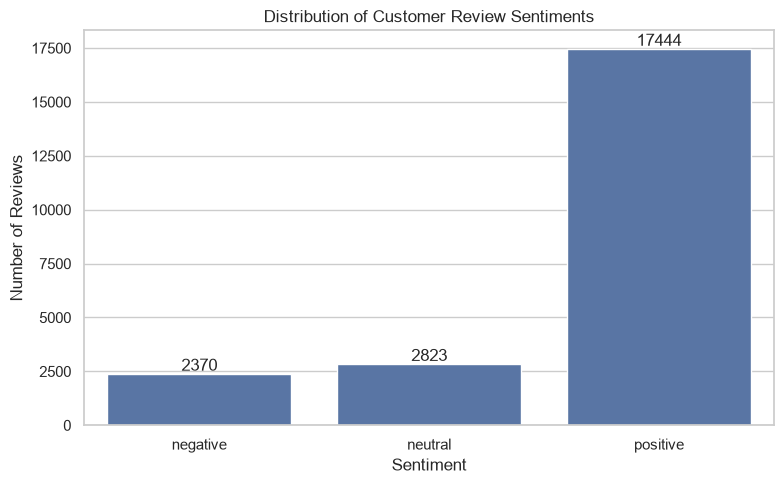

Sentiment distribution:


,Number of Reviews
sentiment,
negative,2370
neutral,2823
positive,17444


In [7]:
sentiment_counts = (
    data["sentiment"]
    .value_counts()
    .reindex(["negative", "neutral", "positive"], fill_value=0)
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

ax.set_title("Distribution of Customer Review Sentiments")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("Sentiment distribution:")
display(sentiment_counts.to_frame("Number of Reviews"))

### Sentiment Distribution Analysis

The bar chart shows the number of reviews in each sentiment category. The class counts help determine whether the dataset is balanced or whether one sentiment category is more common than others. Differences in class size may affect model performance, so precision, recall, and F1-score will also be evaluated.

## 4. Text Preprocessing

Customer reviews may contain uppercase letters, punctuation, HTML entities, URLs, numbers, and common words that contribute little to classification.

The preprocessing pipeline:
1. Converts text to lowercase.
2. Decodes HTML entities and removes HTML tags.
3. Removes URLs.
4. Removes punctuation and digits.
5. Tokenizes text into words.
6. Removes English stopwords.
7. Joins the remaining tokens into cleaned text.

A simple regular-expression tokenizer is used, along with scikit-learn's English stopword list, to avoid requiring additional NLTK corpus downloads.

In [8]:
stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    text = html.unescape(str(text))
    text = text.lower()

    # Remove HTML tags and URLs.
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Keep alphabetic words and tokenize.
    tokens = re.findall(r"[a-z]+", text)

    # Remove common English stopwords.
    tokens = [word for word in tokens if word not in stop_words]

    return " ".join(tokens)

data["clean_text"] = data["text"].apply(preprocess_text)

# Remove records that become empty after preprocessing.
data = data[data["clean_text"].str.strip().ne("")].reset_index(drop=True)

print("Text preprocessing completed!")
display(data[["text", "clean_text", "sentiment"]].head(10))

print("\nRows remaining after preprocessing:", len(data))

Text preprocessing completed!


,text,clean_text,sentiment
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky sexy comfortable,positive
1,Love this dress! it's sooo pretty. i happene...,love dress s sooo pretty happened store m glad...,positive
2,Some major design flaws I had such high hopes ...,major design flaws high hopes dress really wan...,neutral
3,"My favorite buy! I love, love, love this jumps...",favorite buy love love love jumpsuit s fun fli...,positive
4,Flattering shirt This shirt is very flattering...,flattering shirt shirt flattering adjustable t...,positive
5,Not for the very petite I love tracy reese dre...,petite love tracy reese dresses petite just fe...,negative
6,Cagrcoal shimmer fun I aded this in my basket ...,cagrcoal shimmer fun aded basket hte mintue lo...,positive
7,"Shimmer, surprisingly goes with lots I ordered...",shimmer surprisingly goes lots ordered carbon ...,positive
8,Flattering I love this dress. i usually get an...,flattering love dress usually xs runs little s...,positive
9,"Such a fun dress! I'm 5""5' and 125 lbs. i orde...",fun dress m lbs ordered s petite make sure len...,positive



Rows remaining after preprocessing: 22637


### Text Preprocessing Analysis

The cleaned text contains lowercase words with URLs, HTML tags, punctuation, digits, and common English stopwords removed. This reduces irrelevant text and provides a more consistent input for feature extraction. The original review text is retained for interpretation during error analysis.

## 5. WordCloud Visualization

WordClouds show frequently occurring words in each sentiment class. Larger words appear more prominently because they occur more frequently. These visualizations help explore language patterns in positive, negative, and neutral reviews.

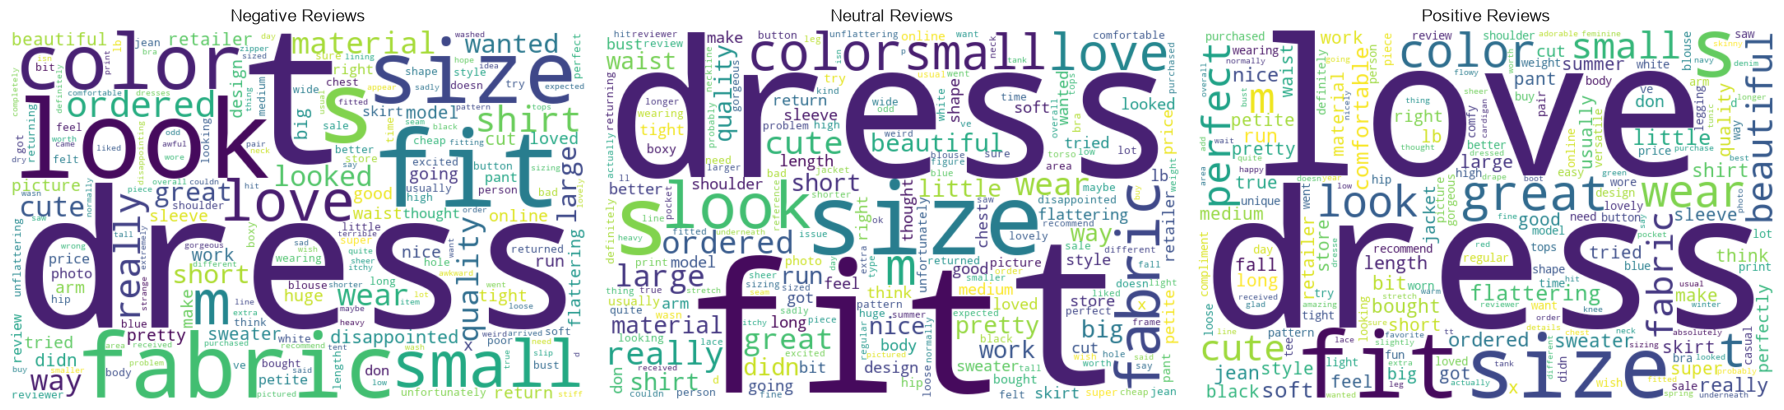

In [10]:
sentiment_order = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, sentiment in zip(axes, sentiment_order):
    text_for_class = " ".join(
        data.loc[data["sentiment"] == sentiment, "clean_text"].tolist()
    )

    if text_for_class.strip():
        wordcloud = WordCloud(
            width=700,
            height=450,
            background_color="white",
            collocations=False,
            random_state=RANDOM_STATE
        ).generate(text_for_class)

        ax.imshow(wordcloud, interpolation="bilinear")
        ax.set_title(f"{sentiment.title()} Reviews")
        ax.axis("off")
    else:
        ax.set_title(f"No {sentiment.title()} Reviews")
        ax.axis("off")

plt.tight_layout()
plt.show()

### WordCloud Analysis

The WordClouds highlight frequently used words in each sentiment group. Positive reviews may contain words expressing satisfaction, negative reviews may contain words describing problems, and neutral reviews may contain more factual descriptions. These patterns are exploratory and do not independently prove the sentiment of a review.

## 6. Feature Extraction Using TF-IDF

Machine learning classifiers require numerical input, so text must be converted into numerical features.

TF-IDF stands for Term Frequency–Inverse Document Frequency.

- Term Frequency (TF) measures how often a word occurs in a review.
- Inverse Document Frequency (IDF) reduces the weight of words that appear in many reviews.
- The combined TF-IDF score gives more importance to words that help distinguish documents.

The TfidfVectorizer converts the cleaned reviews into a sparse numerical matrix. It is fitted only on the training data to prevent information leakage from the test set.

In [11]:
X = data["clean_text"]
y = data["sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training examples:", X_train.shape[0])
print("Testing examples:", X_test.shape[0])
print("TF-IDF training matrix shape:", X_train.shape)
print("TF-IDF testing matrix shape:", X_test.shape)
print("Number of vocabulary features:", len(tfidf.vocabulary_))

Training examples: 18109
Testing examples: 4528
TF-IDF training matrix shape: (18109, 20000)
TF-IDF testing matrix shape: (4528, 20000)
Number of vocabulary features: 20000


### TF-IDF and Train/Test Split Analysis

The dataset was divided into 80% training data and 20% testing data using stratified sampling to preserve class proportions. TF-IDF was fitted on the training reviews and then applied to the test reviews. This ensures the model is evaluated on reviews that were not used to fit the vectorizer.

## 7. Model Training

Two supervised machine-learning classifiers are trained using the TF-IDF features.

### Model 1: Multinomial Naive Bayes
Naive Bayes is a probabilistic classifier commonly used for text classification. It estimates the probability that a review belongs to each sentiment class.

### Model 2: Logistic Regression
Logistic Regression learns relationships between text features and sentiment labels. It supports multiclass classification and provides a useful comparison with Naive Bayes.

Both models use the same training and testing data for a fair comparison.

In [12]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )
}

predictions = {}
results = []

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Both models trained successfully!")
display(results_df.round(4))

Both models trained successfully!


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Naive Bayes,0.7794,0.6865,0.3620,0.3462
1,Logistic Regression,0.8295,0.6664,0.5514,0.5867


## 8. Model Evaluation

The models are evaluated using the following metrics:

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Proportion of predicted examples for a class that are correct.
- **Recall:** Proportion of actual examples for a class that are correctly identified.
- **F1-score:** Harmonic mean of precision and recall.

Macro-averaged precision, recall, and F1-score give equal weight to each sentiment class, making them useful when the class distribution is uneven.

In [13]:
for model_name, y_pred in predictions.items():
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 65)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["negative", "neutral", "positive"],
            zero_division=0,
            digits=4
        )
    )

CLASSIFICATION REPORT: Naive Bayes
              precision    recall  f1-score   support

    negative     0.8205    0.0675    0.1248       474
     neutral     0.4583    0.0195    0.0374       565
    positive     0.7807    0.9991    0.8765      3489

    accuracy                         0.7794      4528
   macro avg     0.6865    0.3620    0.3462      4528
weighted avg     0.7447    0.7794    0.6931      4528

CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

    negative     0.6897    0.4641    0.5549       474
     neutral     0.4424    0.2106    0.2854       565
    positive     0.8673    0.9794    0.9199      3489

    accuracy                         0.8295      4528
   macro avg     0.6664    0.5514    0.5867      4528
weighted avg     0.7957    0.8295    0.8025      4528



### Confusion Matrix Analysis

A confusion matrix compares actual sentiment labels with predicted labels. Correct predictions appear on the diagonal, while off-diagonal values show misclassifications. This helps identify which sentiment categories are most difficult for each model to distinguish.

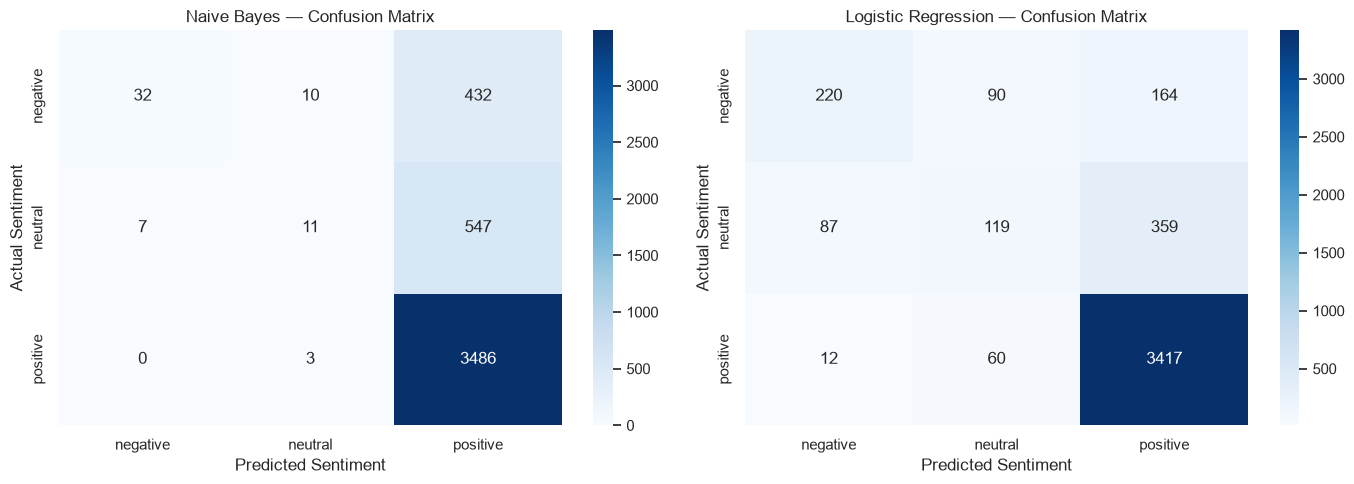

In [14]:
class_labels = ["negative", "neutral", "positive"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

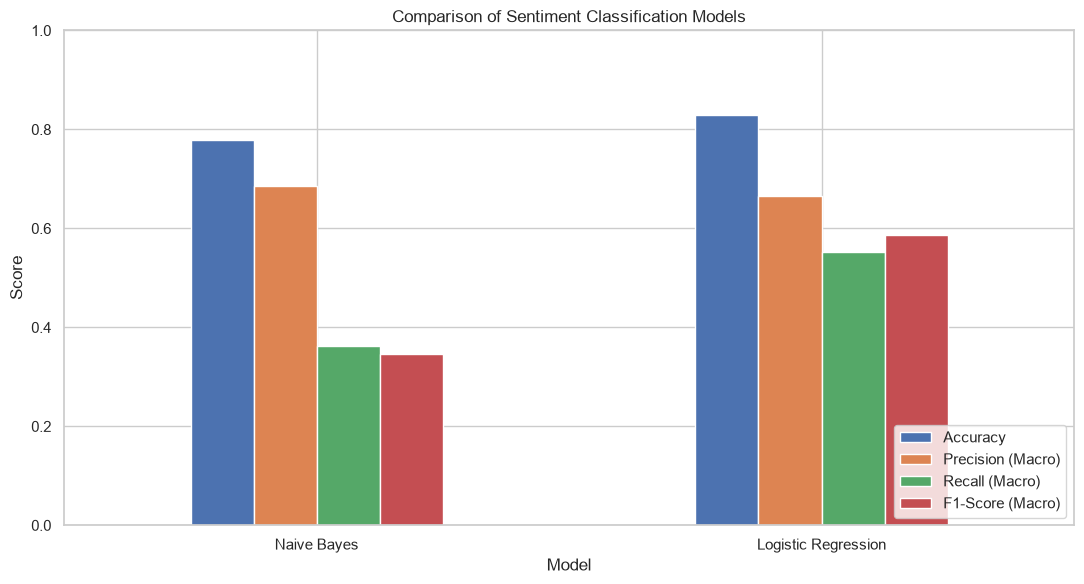

Model comparison:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
1,Logistic Regression,0.8295,0.6664,0.5514,0.5867
0,Naive Bayes,0.7794,0.6865,0.3620,0.3462


In [15]:
metrics_to_plot = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

comparison = results_df.set_index("Model")[metrics_to_plot]

comparison.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparison of Sentiment Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Model comparison:")
display(results_df.sort_values("F1-Score (Macro)", ascending=False).round(4))

### Model Evaluation Analysis

The classification reports show precision, recall, and F1-score for each sentiment class. The confusion matrices identify which categories are confused most often. The comparison chart summarizes the overall performance of Naive Bayes and Logistic Regression.

The best model should be selected based on its macro F1-score, while also considering accuracy and the individual class results. Actual conclusions must be based on the scores produced by this notebook.

## 9. Error Analysis

Error analysis examines reviews that the best-performing model classified incorrectly. Reviewing these examples helps identify possible reasons for prediction errors, such as mixed opinions, ambiguous language, short reviews, or the difference between a product rating and the wording of the review.

In [16]:
# Select the model with the highest macro F1-score.
best_model_name = results_df.loc[
    results_df["F1-Score (Macro)"].idxmax(), "Model"
]

best_predictions = predictions[best_model_name]

error_df = pd.DataFrame({
    "Review": X_test_text.to_numpy(),
    "Actual Sentiment": y_test.to_numpy(),
    "Predicted Sentiment": best_predictions
})

misclassified = error_df[
    error_df["Actual Sentiment"] != error_df["Predicted Sentiment"]
].copy()

print("Best model based on macro F1-score:", best_model_name)
print("Total misclassified reviews:", len(misclassified))

if len(misclassified) > 0:
    print("\nUp to five misclassified examples:")
    display(misclassified.head(5).reset_index(drop=True))
else:
    print("No misclassified reviews were found in this test set.")

Best model based on macro F1-score: Logistic Regression
Total misclassified reviews: 772

Up to five misclassified examples:


,Review,Actual Sentiment,Predicted Sentiment
0,runs big loved idea pants ve looking updated p...,positive,neutral
1,stretchs stretch fast lb order size usually si...,neutral,positive
2,drab color weird fit couldn t make work belted...,negative,neutral
3,runs sizes small best potential dresses ve see...,neutral,positive
4,beautiful tall pants really beautiful material...,neutral,positive


In [17]:
if len(misclassified) > 0:
    print("Actual sentiment vs predicted sentiment:")
    display(
        misclassified.groupby(
            ["Actual Sentiment", "Predicted Sentiment"]
        ).size().reset_index(name="Count")
    )

    print("\nCommon reasons for potential errors:")
    print("- A review may contain both positive and negative opinions.")
    print("- The rating-derived label may not match the wording.")
    print("- Some words can have different meanings in different contexts.")
    print("- Short reviews may not provide enough information.")
    print("- TF-IDF does not fully understand context, sarcasm, or negation.")
else:
    print("There are no errors to inspect for this model on this test set.")

Actual sentiment vs predicted sentiment:


,Actual Sentiment,Predicted Sentiment,Count
0,negative,neutral,90
1,negative,positive,164
2,neutral,negative,87
3,neutral,positive,359
4,positive,negative,12
5,positive,neutral,60



Common reasons for potential errors:
- A review may contain both positive and negative opinions.
- The rating-derived label may not match the wording.
- Some words can have different meanings in different contexts.
- Short reviews may not provide enough information.
- TF-IDF does not fully understand context, sarcasm, or negation.


### Error Analysis Discussion

The misclassified reviews show where the model's predictions differ from the labels derived from ratings.

Possible reasons include mixed opinions, ambiguous wording, negation, limited context, and disagreement between the review text and its rating-based label. TF-IDF represents word importance but does not fully understand context or sarcasm.

The displayed examples should be examined individually before deciding why each prediction was incorrect. These observations can guide improvements to preprocessing, feature extraction, and model selection.

## 10. Export Results

The model comparison results and the best model's test predictions are saved as CSV files. These outputs make it easier to review model performance and inspect individual predictions later.

In [18]:
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation metrics.
metrics_path = output_dir / "model_evaluation_results.csv"
results_df.to_csv(metrics_path, index=False)

# Save actual and predicted sentiment for the best model.
predictions_path = output_dir / "best_model_predictions.csv"
error_df.to_csv(predictions_path, index=False)

# Save the sentiment distribution.
distribution_path = output_dir / "sentiment_distribution.csv"
sentiment_counts.rename_axis("sentiment").reset_index(
    name="count"
).to_csv(distribution_path, index=False)

print("Output files saved successfully:")
print(metrics_path)
print(predictions_path)
print(distribution_path)

Output files saved successfully:
output\model_evaluation_results.csv
output\best_model_predictions.csv
output\sentiment_distribution.csv


## 11. Conclusion

This project applied Natural Language Processing and machine learning to classify customer reviews into negative, neutral, and positive sentiment categories.

The workflow included dataset inspection, rating-based sentiment labeling, text preprocessing, TF-IDF feature extraction, an 80:20 train/test split, and training two classifiers: Multinomial Naive Bayes and Logistic Regression.

Both models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices. Sentiment distribution charts and WordClouds were used to explore the data, while error analysis examined up to five misclassified reviews.

The model with the highest macro F1-score was selected as the best-performing model for this experiment. Its actual performance values are reported in the evaluation table.

### Real-World Applications
- Understanding customer feedback about products and services.
- Identifying recurring customer complaints.
- Monitoring customer satisfaction.
- Supporting review analysis for e-commerce businesses.
- Helping customer support teams prioritize feedback.

### Limitations
Sentiment labels were derived from product ratings, so they may not perfectly reflect the actual sentiment expressed in review text. TF-IDF-based models may also struggle with sarcasm, context, and complex language. Future work could explore lemmatization, n-grams, more advanced NLP models, and manually verified sentiment labels.